In [1]:
import sys
import torch
sys.path.insert(0,"../src")

from cnn_project.train import train_model
from cnn_project.model import EuroSATModel
from cnn_project.evaluate import evaluate_model
from cnn_project.data import create_data_loaders, dataset
from pathlib import Path
import matplotlib.pyplot as plt
import optuna


c:\Users\ghost\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
if torch.cuda.is_available():
    device = torch.device("cuda")
    print("The model is using CUDA")
else:
    device = torch.device("cpu")
    print("The model is using CPU")

torch.manual_seed(42)


The model is using CUDA


In [3]:
import csv
from pathlib import Path

trial_dir = Path("../Checkpoints/optuna_trials")
trial_dir.mkdir(parents=True, exist_ok=True)

def objective(trial):
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    gamma = trial.suggest_float("gamma", 0.5, 0.95)
    batch_size = trial.suggest_categorical("batch_size", [64, 128, 256, 512])

    train_loader, val_loader, _ = create_data_loaders(batch_size=batch_size)
    trial_model = EuroSATModel().to(device)
    history = train_model(
        model=trial_model,
        train_loader=train_loader,
        val_loader=val_loader,
        device=device,
        epochs=30,
        lr=lr,
        gamma=gamma,
    )

    csv_path = trial_dir / f"trial_{trial.number:03d}_history.csv"
    with csv_path.open("w", newline="") as file:
        writer = csv.writer(file)
        writer.writerow(history.keys())
        writer.writerows(zip(*history.values()))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["epoch"], history["train_loss"], label="Train")
    axes[0].plot(history["epoch"], history["val_loss"], label="Validation")
    axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Loss")
    axes[1].plot(history["epoch"], history["train_accuracy"], label="Train")
    axes[1].plot(history["epoch"], history["val_accuracy"], label="Validation")
    axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy", ylim=(0, 1))
    for ax in axes:
        ax.set_xlim(1, 30)
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(f"Trial {trial.number}: lr={lr:.2g}, gamma={gamma:.3f}, batch={batch_size}")
    fig.tight_layout()
    png_path = trial_dir / f"trial_{trial.number:03d}_curves.png"
    fig.savefig(png_path, dpi=150)
    plt.close(fig)
    print(f"Saved {png_path} and {csv_path}")

    return max(history["val_accuracy"])

study = optuna.create_study(
    direction="maximize",
    storage="sqlite:///eurosat_optuna.db",
    study_name="eurosat_cnn",
    load_if_exists=True,
)
study.optimize(objective, n_trials=20)
print("Best validation accuracy:", study.best_value)
print("Best parameters:", study.best_params)


[I 2026-10-25 12:34:58,118] A new study created in RDB with name: eurosat_cnn


Training model...
Epoch 1, Loss: 0.9730, Accuracy: 0.6420, LR: 0.0019802915, Val loss: 0.9995, Val accuracy: 0.6170
Epoch 2, Loss: 0.6363, Accuracy: 0.7721, LR: 0.0019802915, Val loss: 0.7238, Val accuracy: 0.7363
Epoch 3, Loss: 0.5672, Accuracy: 0.7973, LR: 0.0019802915, Val loss: 0.6708, Val accuracy: 0.7630
Epoch 4, Loss: 0.4830, Accuracy: 0.8310, LR: 0.0016904803, Val loss: 0.5230, Val accuracy: 0.8119
Epoch 5, Loss: 0.4614, Accuracy: 0.8375, LR: 0.0016904803, Val loss: 0.4943, Val accuracy: 0.8237
Epoch 6, Loss: 0.4403, Accuracy: 0.8458, LR: 0.0016904803, Val loss: 0.9826, Val accuracy: 0.7407
Epoch 7, Loss: 0.3826, Accuracy: 0.8675, LR: 0.0014430824, Val loss: 0.8389, Val accuracy: 0.7774
Epoch 8, Loss: 0.3736, Accuracy: 0.8665, LR: 0.0014430824, Val loss: 0.4707, Val accuracy: 0.8326
Epoch 9, Loss: 0.3460, Accuracy: 0.8800, LR: 0.0014430824, Val loss: 0.2991, Val accuracy: 0.8993
Epoch 10, Loss: 0.3212, Accuracy: 0.8877, LR: 0.0012318906, Val loss: 0.3757, Val accuracy: 0.8726
E

[I 2026-10-25 12:40:12,327] Trial 0 finished with value: 0.9362962962962963 and parameters: {'lr': 0.0019802914832522606, 'gamma': 0.8536522834714122, 'batch_size': 512}. Best is trial 0 with value: 0.9362962962962963.


Training model...
Epoch 1, Loss: 0.9665, Accuracy: 0.6553, LR: 0.0019537493, Val loss: 0.8619, Val accuracy: 0.6985
Epoch 2, Loss: 0.6935, Accuracy: 0.7529, LR: 0.0019537493, Val loss: 0.6247, Val accuracy: 0.7659
Epoch 3, Loss: 0.6045, Accuracy: 0.7865, LR: 0.0019537493, Val loss: 0.6619, Val accuracy: 0.7759
Epoch 4, Loss: 0.5071, Accuracy: 0.8211, LR: 0.0018270702, Val loss: 0.4903, Val accuracy: 0.8374
Epoch 5, Loss: 0.4599, Accuracy: 0.8402, LR: 0.0018270702, Val loss: 0.9946, Val accuracy: 0.7626
Epoch 6, Loss: 0.4130, Accuracy: 0.8543, LR: 0.0018270702, Val loss: 0.8821, Val accuracy: 0.7585
Epoch 7, Loss: 0.3817, Accuracy: 0.8656, LR: 0.0017086048, Val loss: 0.4023, Val accuracy: 0.8630
Epoch 8, Loss: 0.3486, Accuracy: 0.8783, LR: 0.0017086048, Val loss: 0.5223, Val accuracy: 0.8204
Epoch 9, Loss: 0.3213, Accuracy: 0.8876, LR: 0.0017086048, Val loss: 0.4303, Val accuracy: 0.8507
Epoch 10, Loss: 0.2962, Accuracy: 0.8959, LR: 0.0015978206, Val loss: 0.2740, Val accuracy: 0.9056
E

[I 2026-10-25 12:45:17,720] Trial 1 finished with value: 0.947037037037037 and parameters: {'lr': 0.001953749334769624, 'gamma': 0.9351610108210506, 'batch_size': 64}. Best is trial 1 with value: 0.947037037037037.


...

Training model...
Epoch 1, Loss: 1.0315, Accuracy: 0.6144, LR: 0.0034456216, Val loss: 1.0081, Val accuracy: 0.6493
Epoch 2, Loss: 0.6649, Accuracy: 0.7585, LR: 0.0034456216, Val loss: 1.0828, Val accuracy: 0.6522
Epoch 3, Loss: 0.6044, Accuracy: 0.7839, LR: 0.0034456216, Val loss: 1.2164, Val accuracy: 0.6874
Epoch 4, Loss: 0.5157, Accuracy: 0.8184, LR: 0.0017496047, Val loss: 0.6184, Val accuracy: 0.7789
Epoch 5, Loss: 0.4319, Accuracy: 0.8451, LR: 0.0017496047, Val loss: 0.4672, Val accuracy: 0.8326
Epoch 6, Loss: 0.4110, Accuracy: 0.8563, LR: 0.0017496047, Val loss: 0.4522, Val accuracy: 0.8404
Epoch 7, Loss: 0.3562, Accuracy: 0.8751, LR: 0.0008884077, Val loss: 0.3838, Val accuracy: 0.8644
Epoch 8, Loss: 0.3381, Accuracy: 0.8794, LR: 0.0008884077, Val loss: 0.3232, Val accuracy: 0.8800
Epoch 9, Loss: 0.3189, Accuracy: 0.8869, LR: 0.0008884077, Val loss: 0.3964, Val accuracy: 0.8674
Epoch 10, Loss: 0.3013, Accuracy: 0.8944, LR: 0.0004511123, Val loss: 0.2887, Val accuracy: 0.8996
E

[I 2026-10-25 14:24:11,178] Trial 18 finished with value: 0.9159259259259259 and parameters: {'lr': 0.003445621595814228, 'gamma': 0.507776216503999, 'batch_size': 512}. Best is trial 11 with value: 0.9577777777777777.


Training model...
Epoch 1, Loss: 1.0211, Accuracy: 0.6375, LR: 0.0003953753, Val loss: 0.6715, Val accuracy: 0.7641
Epoch 2, Loss: 0.6330, Accuracy: 0.7741, LR: 0.0003953753, Val loss: 0.5821, Val accuracy: 0.7981
Epoch 3, Loss: 0.5476, Accuracy: 0.8078, LR: 0.0003953753, Val loss: 0.5228, Val accuracy: 0.8181
Epoch 4, Loss: 0.4769, Accuracy: 0.8326, LR: 0.0002865435, Val loss: 0.4200, Val accuracy: 0.8570
Epoch 5, Loss: 0.4368, Accuracy: 0.8486, LR: 0.0002865435, Val loss: 0.3981, Val accuracy: 0.8678
Epoch 6, Loss: 0.4161, Accuracy: 0.8538, LR: 0.0002865435, Val loss: 0.4710, Val accuracy: 0.8307
Epoch 7, Loss: 0.3955, Accuracy: 0.8631, LR: 0.0002076690, Val loss: 0.3591, Val accuracy: 0.8822
Epoch 8, Loss: 0.3681, Accuracy: 0.8704, LR: 0.0002076690, Val loss: 0.3439, Val accuracy: 0.8800
Epoch 9, Loss: 0.3546, Accuracy: 0.8754, LR: 0.0002076690, Val loss: 0.3472, Val accuracy: 0.8848
Epoch 10, Loss: 0.3365, Accuracy: 0.8832, LR: 0.0001505056, Val loss: 0.2999, Val accuracy: 0.9048
E

[I 2026-10-25 14:29:28,464] Trial 19 finished with value: 0.9262962962962963 and parameters: {'lr': 0.00039537527663787293, 'gamma': 0.7247380352831508, 'batch_size': 256}. Best is trial 11 with value: 0.9577777777777777.


Best validation accuracy: 0.9577777777777777
Best parameters: {'lr': 0.006331992329769813, 'gamma': 0.6962221733165475, 'batch_size': 64}


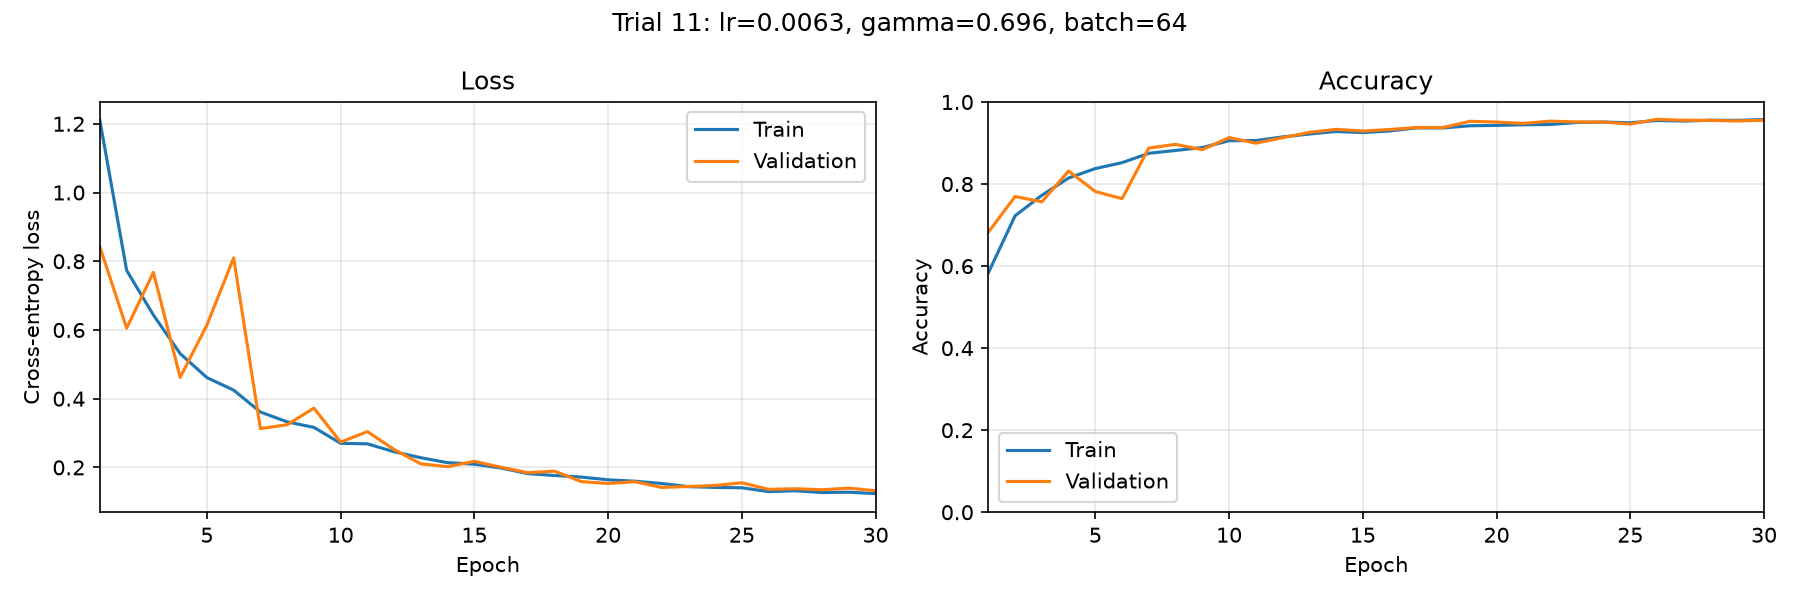

In [4]:
from IPython.display import Image, display

display(Image(filename="../Checkpoints/optuna_trials/trial_011_curves.png"))

## Compare all trials

Run this cell after the search. It plots all saved trial curves with the batch size, learning rate, gamma, and best validation accuracy for each line.


c:\Users\ghost\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


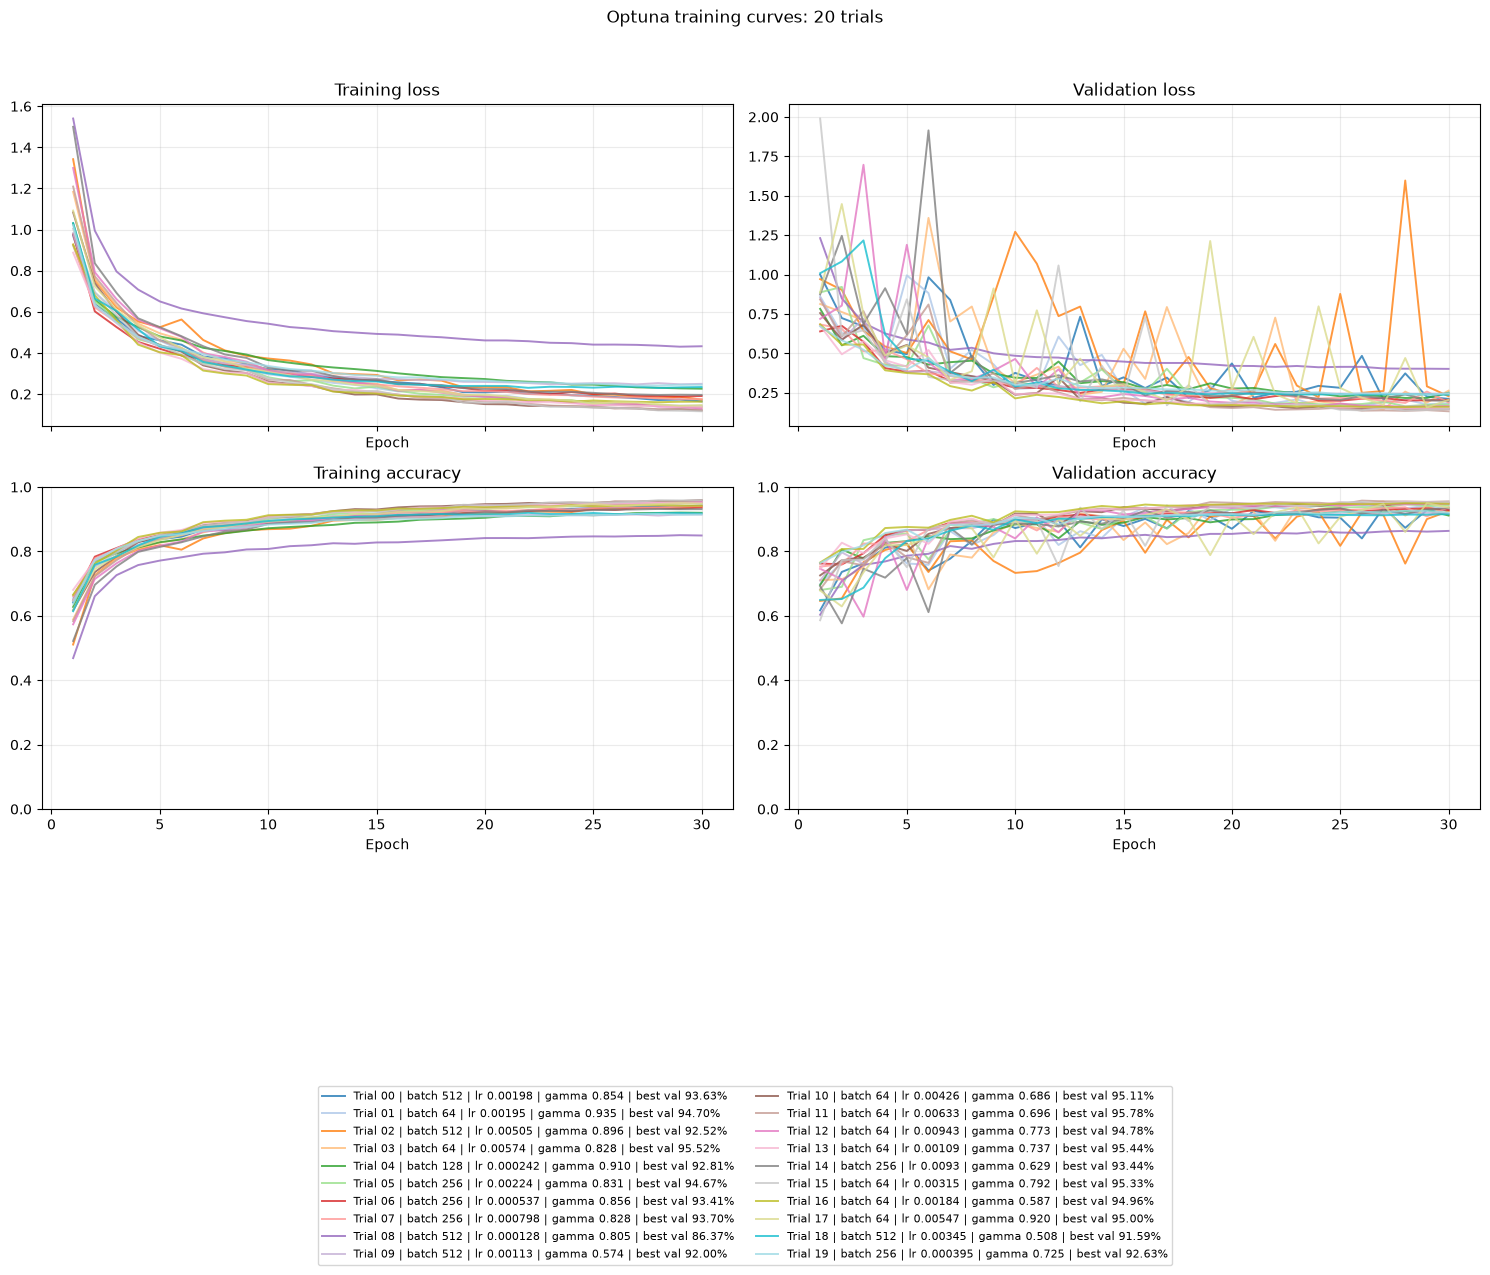

Saved ..\Checkpoints\optuna_trials\all_trials_curves.png


In [1]:
import csv
import matplotlib.pyplot as plt
import optuna
from pathlib import Path

trial_dir = Path("../Checkpoints/optuna_trials")
files = sorted(trial_dir.glob("trial_*_history.csv"))
if not files:
    raise FileNotFoundError(f"No trial histories found in {trial_dir}")

saved_study = optuna.load_study(
    study_name="eurosat_cnn",
    storage="sqlite:///eurosat_optuna.db",
)
trials = {trial.number: trial for trial in saved_study.trials}
metrics = [
    ("train_loss", "Training loss"),
    ("val_loss", "Validation loss"),
    ("train_accuracy", "Training accuracy"),
    ("val_accuracy", "Validation accuracy"),
]
fig, axes = plt.subplots(2, 2, figsize=(15, 13), sharex=True)
colors = plt.get_cmap("tab20")

for index, path in enumerate(files):
    with path.open(newline="") as file:
        rows = list(csv.DictReader(file))
    epochs = [int(row["epoch"]) for row in rows]
    trial_number = int(path.stem.split("_")[1])
    trial = trials[trial_number]
    params = trial.params
    label = (f"Trial {trial_number:02d} | batch {params['batch_size']} | "
             f"lr {params['lr']:.3g} | gamma {params['gamma']:.3f} | "
             f"best val {trial.value:.2%}")
    for ax, (key, title) in zip(axes.flat, metrics):
        values = [float(row[key]) for row in rows]
        ax.plot(epochs, values, color=colors(index % 20), alpha=0.8,
                linewidth=1.4, label=label)
        ax.set_title(title)
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.25)

for ax in axes[1]:
    ax.set_ylim(0, 1)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, fontsize=8,
           bbox_to_anchor=(0.5, 0.01))
fig.suptitle(f"Optuna training curves: {len(files)} trials")
fig.tight_layout(rect=(0, 0.32, 1, 0.96))
summary_path = trial_dir / "all_trials_curves.png"
fig.savefig(summary_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved {summary_path}")
